# Clase 7 · Laboratorio — Modelos No Supervisados sobre Saber 11

**Trabajo en parejas · 90 min.**

En la pre-clase viste todos los modelos funcionando. En este laboratorio analizarás los datos desde ángulos más complejos: ¿cuántos perfiles de colegios existen en Colombia? ¿Qué departamentos son anomalías? ¿Se puede predecir el cluster de un nuevo estudiante?

**Checkpoint del profesor a los 50 min** (después de la Tarea 3).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings; warnings.filterwarnings('ignore')

df = pd.read_csv("../saber11_muestra_500k (1).csv")
print(f"Dataset original: {len(df):,} filas × {df.shape[1]} columnas")

# La muestra trae filas duplicadas (el mismo estudiante repetido): se eliminan
print(f"Filas duplicadas: {df.duplicated().sum():,}")
df = df.drop_duplicates()

df["ESTRATO_NUM"] = df["FAMI_ESTRATOVIVIENDA"].str.extract(r"(\d+)").astype(float)
PUNTAJES = ["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES",
            "PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]
print(f"Dataset sin duplicados: {len(df):,} filas × {df.shape[1]} columnas")

Dataset original: 500,000 filas × 51 columnas


Filas duplicadas: 128,843


Dataset sin duplicados: 371,157 filas × 52 columnas


## Tarea 1 (20 min) — Perfiles de colegios en Colombia

En lugar de segmentar estudiantes (como en la pre-clase), segmenta **colegios** usando su puntaje promedio.

1. Agrupa el dataset por `COLE_NOMBRE_ESTABLECIMIENTO` y calcula el promedio de los 5 puntajes y el estrato promedio. Filtra colegios con al menos 30 estudiantes.
2. Escala las variables.
3. Aplica K-Means y usa el método del codo + Silhouette para elegir K (entre 2 y 8).
4. Para cada cluster: ¿qué tipo de colegio describe? Muestra el promedio de las variables y la distribución de `COLE_NATURALEZA` y `COLE_AREA_UBICACION` dentro de cada cluster.
5. ¿Cuáles son los 5 colegios "más típicos" del cluster de mayor puntaje? ¿Los reconoces?

Colegios con ≥30 estudiantes: 4,295


K=2  inercia=11,565  silhouette=0.4891


K=3  inercia=6,980  silhouette=0.4173


K=4  inercia=5,294  silhouette=0.3624


K=5  inercia=4,366  silhouette=0.3280


K=6  inercia=3,856  silhouette=0.2955


K=7  inercia=3,435  silhouette=0.3026


K=8  inercia=3,111  silhouette=0.2945


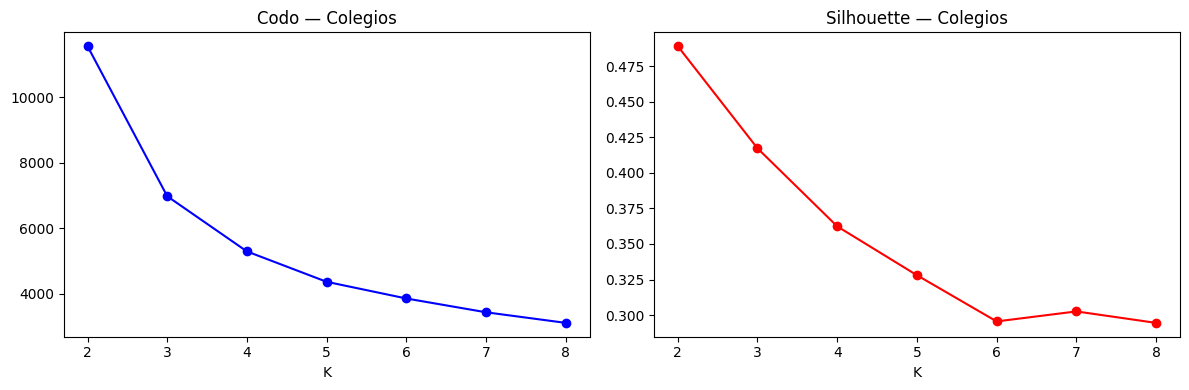


=== Perfil por cluster ===
         PUNT_LECTURA_CRITICA  PUNT_MATEMATICAS  PUNT_C_NATURALES  \
cluster                                                             
0                        47.2              44.3              43.4   
1                        62.7              62.4              59.4   
2                        54.4              52.7              50.4   

         PUNT_SOCIALES_CIUDADANAS  PUNT_INGLES  ESTRATO_NUM  
cluster                                                      
0                            41.4         42.4          1.8  
1                            58.7         65.1          3.0  
2                            48.9         50.7          2.0  

Colegios por cluster: {0: 1688, 1: 649, 2: 1958}

=== Naturaleza por cluster ===
COLE_NATURALEZA  NO OFICIAL  OFICIAL
cluster                             
0                       223     1465
1                       466      183
2                       212     1746

=== Área de ubicación por cluster ===
COLE_AREA_

In [2]:
# TODO 1: agregar por colegio (≥30 estudiantes)
# Se agrupa por código DANE porque hay nombres de colegio repetidos en distintos municipios
colegios = df.groupby("COLE_COD_DANE_ESTABLECIMIENTO").agg(
    COLE_NOMBRE_ESTABLECIMIENTO=("COLE_NOMBRE_ESTABLECIMIENTO","first"),
    COLE_MCPIO_UBICACION=("COLE_MCPIO_UBICACION","first"),
    n_estudiantes=("PUNT_MATEMATICAS","count"),
    COLE_NATURALEZA=("COLE_NATURALEZA","first"),
    COLE_AREA_UBICACION=("COLE_AREA_UBICACION","first"),
    COLE_JORNADA=("COLE_JORNADA","first"),
    **{p: (p,"mean") for p in PUNTAJES},
    ESTRATO_NUM=("ESTRATO_NUM","mean")
).query("n_estudiantes >= 30").dropna()
print(f"Colegios con ≥30 estudiantes: {len(colegios):,}")

# TODO 2: escalar
X_colegios = StandardScaler().fit_transform(colegios[PUNTAJES + ["ESTRATO_NUM"]])

# TODO 3: Elbow + Silhouette
inercias_c, silhouettes_c = [], []
for k in range(2, 9):
    km_c = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels_c = km_c.fit_predict(X_colegios)
    inercias_c.append(km_c.inertia_)
    silhouettes_c.append(silhouette_score(X_colegios, labels_c))
    print(f"K={k}  inercia={km_c.inertia_:,.0f}  silhouette={silhouettes_c[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 9), inercias_c, "b-o"); axes[0].set_title("Codo — Colegios"); axes[0].set_xlabel("K")
axes[1].plot(range(2, 9), silhouettes_c, "r-o"); axes[1].set_title("Silhouette — Colegios"); axes[1].set_xlabel("K")
plt.tight_layout(); plt.show()

# TODO 4: K-Means final + perfil
K_col = 3  # tu K elegido (ver justificación abajo)
km_col = KMeans(n_clusters=K_col, n_init=10, random_state=42)
colegios["cluster"] = km_col.fit_predict(X_colegios)

print("\n=== Perfil por cluster ===")
print(colegios.groupby("cluster")[PUNTAJES + ["ESTRATO_NUM"]].mean().round(1))
print("\nColegios por cluster:", colegios["cluster"].value_counts().sort_index().to_dict())
print("\n=== Naturaleza por cluster ===")
print(colegios.groupby(["cluster","COLE_NATURALEZA"]).size().unstack(fill_value=0))
print("\n=== Área de ubicación por cluster ===")
print(colegios.groupby(["cluster","COLE_AREA_UBICACION"]).size().unstack(fill_value=0))

# TODO 5: los 5 colegios más típicos del cluster élite (los más cercanos a su centroide)
cluster_elite = colegios.groupby("cluster")[PUNTAJES].mean().sum(axis=1).idxmax()
mask_elite = (colegios["cluster"] == cluster_elite).values
distancias = np.linalg.norm(X_colegios[mask_elite] - km_col.cluster_centers_[cluster_elite], axis=1)
elite = colegios[mask_elite].assign(distancia=distancias)
print(f"\n=== 5 colegios más típicos del cluster élite (cluster {cluster_elite}) ===")
print(elite.nsmallest(5, "distancia")[["COLE_NOMBRE_ESTABLECIMIENTO","COLE_MCPIO_UBICACION",
                                       "COLE_NATURALEZA","distancia"] + PUNTAJES].round(1).to_string(index=False))

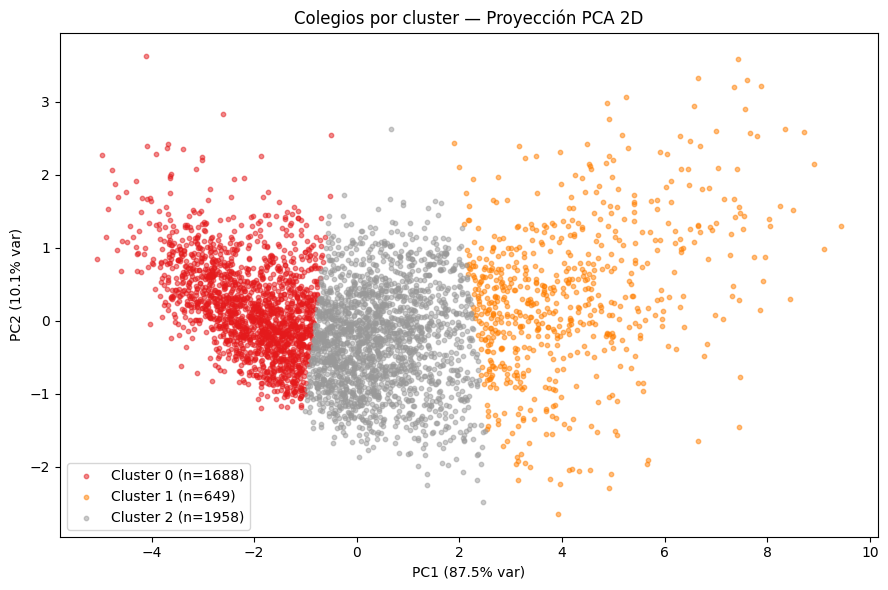

In [3]:
# Visualización PCA de clusters de colegios
pca_col = PCA(n_components=2)
coords_col = pca_col.fit_transform(X_colegios)
colores_col = plt.cm.Set1(np.linspace(0,1,K_col))

fig, ax = plt.subplots(figsize=(9,6))
for k in range(K_col):
    mask = colegios["cluster"] == k
    ax.scatter(coords_col[mask,0], coords_col[mask,1], alpha=0.5, s=10,
               color=colores_col[k], label=f"Cluster {k} (n={mask.sum()})")
ax.set_xlabel(f"PC1 ({pca_col.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca_col.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title("Colegios por cluster — Proyección PCA 2D")
ax.legend(); plt.tight_layout(); plt.show()

**Pregunta analítica:** ¿Los clusters de colegios coinciden con lo que esperarías según la naturaleza del colegio (oficial vs privado) o su ubicación (urbano vs rural)?

**Nota sobre los datos:** antes de agrupar se eliminaron 128.843 filas duplicadas (el 25,8 % de la muestra), porque si no los colegios aparecen con más estudiantes de los que tienen. Además se agrupó por código DANE y no por nombre, porque hay nombres como "INSTITUCION EDUCATIVA SAN JOSE" que se repiten en varios municipios y se mezclarían.

**¿Qué K elegimos?** El Silhouette más alto es K=2 (0,489), pero con 2 grupos solo se separan colegios "buenos" y "malos". En el codo la inercia baja mucho de K=2 a K=3 (11.565 → 6.980) y de ahí en adelante baja poco, y K=3 sigue teniendo buen Silhouette (0,417). Por eso elegimos **K=3**.

**Perfil de los clusters:**
- **Cluster 0 – Bajo desempeño (1.688 colegios):** puntajes entre 41 y 47, estrato promedio 1,8. Casi todos oficiales (87 %) y es el cluster con más colegios rurales (22 %).
- **Cluster 2 – Desempeño medio (1.958 colegios):** puntajes entre 49 y 54, estrato 2,0. Principalmente oficiales (89 %) y urbanos (93 %).
- **Cluster 1 – Alto desempeño / élite (649 colegios):** puntajes alrededor de 59-65 (inglés 65), estrato 3,0. El 72 % son no oficiales y casi todos urbanos (97 %).

**Top 5 más típicos del cluster élite** (los más cercanos al centroide): Inst. Téc. Ind. Centro Don Bosco, Col. Superior Americano, Colegio San Felipe Neri y Liceo Mayor Andino (Bogotá) y Col. La Salle (Bello). Son colegios privados urbanos conocidos. Son los "típicos" del grupo, no los mejores del país: están en el promedio del cluster élite.

**Respuesta:** Sí coinciden en buena parte. El cluster alto es mayoritariamente privado y urbano, y el bajo es oficial y con más presencia rural. Pero no es una regla exacta: hay 183 colegios oficiales en el cluster élite y 223 privados en el cluster bajo, así que la naturaleza del colegio por sí sola no explica todo. El estrato también influye mucho.

## Tarea 2 (15 min) — Anomalías en el perfil de colegios

Usa DBSCAN sobre el mismo dataset de colegios para detectar colegios con perfiles inusuales.

1. Aplica DBSCAN con `eps=1.0, min_samples=3`.
2. ¿Cuántos colegios son "ruido" (-1)?
3. Muestra el perfil de los colegios anómalos: ¿tienen puntajes extremadamente altos, extremadamente bajos, o una combinación inusual?
4. ¿Qué tienen en común los colegios etiquetados como ruido? (Revisa `COLE_NATURALEZA`, `COLE_AREA_UBICACION`, `COLE_JORNADA`).

In [4]:
# TODO 1: DBSCAN sobre X_colegios
db = DBSCAN(eps=1.0, min_samples=3)
colegios["cluster_db"] = db.fit_predict(X_colegios)

# TODO 2: conteo de ruido
n_anomalos = (colegios["cluster_db"] == -1).sum()
print(f"Colegios anómalos (ruido): {n_anomalos} de {len(colegios)} ({n_anomalos/len(colegios)*100:.1f}%)")

# TODO 3: perfil de anomalías
anomalos = colegios[colegios["cluster_db"] == -1]
normales = colegios[colegios["cluster_db"] != -1]
print("\nPerfil anómalos vs normales:")
comp = pd.concat([
    anomalos[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Anómalos"),
    normales[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Normales")], axis=1).round(1)
print(comp)
print("\nPuntaje promedio de los anómalos (ordenado):")
print(anomalos[PUNTAJES].mean(axis=1).describe().round(1))

# TODO 4: características comunes de anómalos (% dentro de anómalos vs normales)
for col in ["COLE_NATURALEZA", "COLE_AREA_UBICACION", "COLE_JORNADA"]:
    print(f"\n{col}:")
    print(pd.concat([anomalos[col].value_counts(normalize=True).rename("Anómalos %"),
                     normales[col].value_counts(normalize=True).rename("Normales %")], axis=1).fillna(0).mul(100).round(1))

Colegios anómalos (ruido): 7 de 4295 (0.2%)

Perfil anómalos vs normales:
                          Anómalos  Normales
PUNT_LECTURA_CRITICA          50.7      52.8
PUNT_MATEMATICAS              49.1      50.9
PUNT_C_NATURALES              47.7      49.0
PUNT_SOCIALES_CIUDADANAS      46.2      47.4
PUNT_INGLES                   47.3      49.6
ESTRATO_NUM                    3.1       2.1

Puntaje promedio de los anómalos (ordenado):
count     7.0
mean     48.2
std      15.1
min      32.3
25%      37.2
50%      43.8
75%      58.2
max      70.6
dtype: float64

COLE_NATURALEZA:
                 Anómalos %  Normales %
COLE_NATURALEZA                        
OFICIAL                71.4        79.0
NO OFICIAL             28.6        21.0

COLE_AREA_UBICACION:
                     Anómalos %  Normales %
COLE_AREA_UBICACION                        
URBANO                     57.1        87.7
RURAL                      42.9        12.3

COLE_JORNADA:
              Anómalos %  Normales %
COLE_JORNA

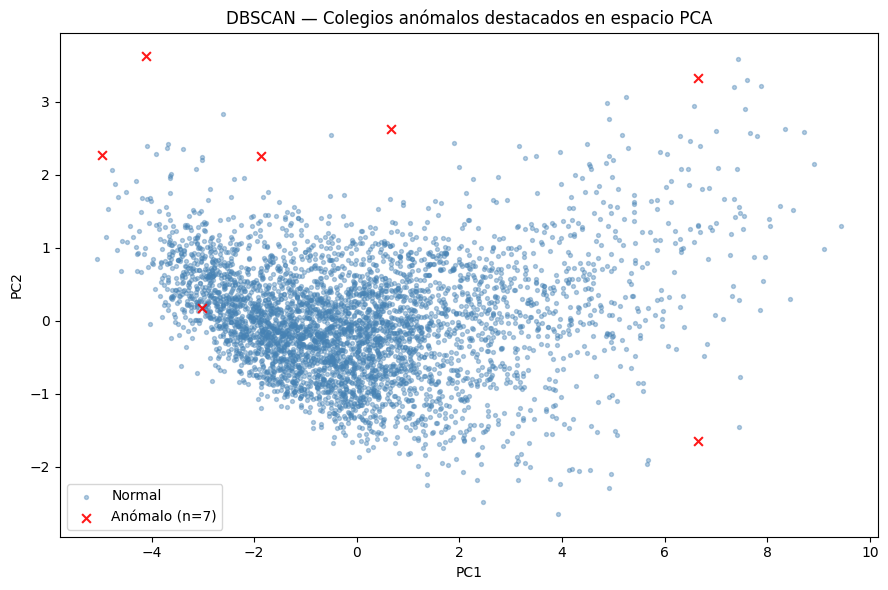

In [5]:
# Visualizar anómalos en espacio PCA
fig, ax = plt.subplots(figsize=(9,6))
mask_normal = colegios["cluster_db"] != -1
mask_anomalo = colegios["cluster_db"] == -1
ax.scatter(coords_col[mask_normal,0], coords_col[mask_normal,1],
           alpha=0.4, s=8, c="steelblue", label="Normal")
ax.scatter(coords_col[mask_anomalo,0], coords_col[mask_anomalo,1],
           alpha=0.9, s=40, c="red", marker="x", linewidths=1.5, label=f"Anómalo (n={mask_anomalo.sum()})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("DBSCAN — Colegios anómalos destacados en espacio PCA")
ax.legend(); plt.tight_layout(); plt.show()

**Análisis Tarea 2:**

- Con `eps=1.0, min_samples=3` DBSCAN deja solo **7 colegios como ruido (0,2 %)**. Casi todos los colegios forman un único grupo denso, porque los perfiles cambian de forma gradual y no hay saltos grandes.
- Los anómalos **no son todos altos ni todos bajos**: su puntaje promedio va de 32 a 71. Hay colegios con puntajes muy bajos y otros muy altos. Lo que tienen en común es una **combinación inusual**: su estrato promedio es 3,1 (contra 2,1 de los normales), o sea, el estrato no coincide con lo que se esperaría por sus puntajes.
- **Rasgos en común:** hay más rurales que en el resto (43 % contra 12 %) y más jornada sabatina (14 % contra 5 %). Ninguno es de jornada única, tarde o noche.
- Conclusión: los anómalos de DBSCAN son colegios **"distintos", no necesariamente "malos"**. Habría que revisarlos uno por uno, porque también pueden ser errores de registro (por ejemplo, un estrato mal reportado).

## Tarea 3 (15 min) — ¿Suave o duro?

Usando el mismo K que encontraste en la Tarea 1:

1. Aplica GMM con el mismo K sobre los colegios.
2. Compara las métricas (Silhouette, Davies-Bouldin) de K-Means vs GMM.
3. Identifica los colegios con **alta incertidumbre** (probabilidad máxima < 0.70). ¿Qué tipo de colegio tiende a quedar "entre dos clusters"?
4. ¿En qué caso preferirías el output probabilístico de GMM sobre el duro de K-Means para tomar decisiones de política educativa?

In [6]:
# TODO 1: GMM
gmm_col = GaussianMixture(n_components=K_col, random_state=42)
gmm_col.fit(X_colegios)
colegios["cluster_gmm"] = gmm_col.predict(X_colegios)

# TODO 2: métricas
sil_km_c  = silhouette_score(X_colegios, colegios["cluster"])
sil_gmm_c = silhouette_score(X_colegios, colegios["cluster_gmm"])
db_km_c   = davies_bouldin_score(X_colegios, colegios["cluster"])
db_gmm_c  = davies_bouldin_score(X_colegios, colegios["cluster_gmm"])
print(f"K-Means  → Silhouette: {sil_km_c:.4f}  |  Davies-Bouldin: {db_km_c:.4f}")
print(f"GMM      → Silhouette: {sil_gmm_c:.4f}  |  Davies-Bouldin: {db_gmm_c:.4f}")

# TODO 3: colegios inciertos
proba = gmm_col.predict_proba(X_colegios)
colegios["max_proba"] = proba.max(axis=1)
inciertos = colegios[colegios["max_proba"] < 0.70]
print(f"\nColegios inciertos (prob < 70%): {len(inciertos)} ({len(inciertos)/len(colegios)*100:.1f}%)")
print(inciertos[["COLE_NATURALEZA","COLE_AREA_UBICACION","max_proba"] + PUNTAJES].round(2).head(10))

print("\nPerfil inciertos vs todos:")
print(pd.concat([inciertos[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Inciertos"),
                 colegios[PUNTAJES + ["ESTRATO_NUM"]].mean().rename("Todos")], axis=1).round(1))
print("\nNaturaleza de inciertos (%):")
print(inciertos["COLE_NATURALEZA"].value_counts(normalize=True).mul(100).round(1))
print("\nCluster GMM de los inciertos:")
print(inciertos["cluster_gmm"].value_counts())

K-Means  → Silhouette: 0.4173  |  Davies-Bouldin: 0.7859
GMM      → Silhouette: 0.3478  |  Davies-Bouldin: 0.8754

Colegios inciertos (prob < 70%): 938 (21.8%)
                              COLE_NATURALEZA COLE_AREA_UBICACION  max_proba  \
COLE_COD_DANE_ESTABLECIMIENTO                                                  
105001000485                          OFICIAL              URBANO       0.60   
105001000841                          OFICIAL              URBANO       0.58   
105001001155                          OFICIAL              URBANO       0.58   
105001001279                          OFICIAL              URBANO       0.55   
105001001660                          OFICIAL              URBANO       0.60   
105001001805                          OFICIAL              URBANO       0.56   
105001001881                          OFICIAL              URBANO       0.64   
105001002348                          OFICIAL              URBANO       0.52   
105001002356                          OF

**Resultados:**
- K-Means: Silhouette 0,417 y Davies-Bouldin 0,786. GMM: Silhouette 0,348 y Davies-Bouldin 0,875. **K-Means sale mejor en las dos métricas** con estos datos.
- El **21,8 % de los colegios (938) queda con probabilidad máxima < 0,70**. Su perfil es casi igual al promedio nacional (por ejemplo, matemáticas 51,0 contra 50,9), son en su mayoría **oficiales (86 %) y urbanos**, y caen sobre todo en los clusters GMM 2 (medio, 496) y 0 (bajo, 335). Son los colegios "de la frontera": ni claramente bajos ni claramente medios.

**¿Cuándo preferirías GMM sobre K-Means para política educativa?**

Cuando la decisión cambia según qué tan seguro estés de dónde está el colegio. Por ejemplo, si el Ministerio va a dar recursos a los colegios de bajo desempeño, K-Means mete o saca a cada colegio de forma tajante. En cambio, GMM muestra que hay un 22 % de colegios que están en el límite. A esos se les podría hacer una visita o un diagnóstico antes de decidir, o darles un apoyo intermedio. También sirve para seguimiento: si la probabilidad de que un colegio pertenezca al grupo bajo sube de un año a otro, es una alerta temprana. K-Means es mejor cuando solo se necesita una etiqueta simple para un reporte.

## Checkpoint del profesor (10 min)

Discutimos:
- ¿Qué K elegiste y por qué (Elbow o Silhouette)?
- ¿Los colegios anómalos de DBSCAN son "malos" o simplemente "distintos"?
- ¿Tiene sentido usar PCA antes de aplicar clustering? ¿Cuándo sí y cuándo no?

**Nuestras respuestas al checkpoint:**
- **K elegido:** K=3. Silhouette sugería K=2, pero el codo muestra que el cambio grande está en K=3 y así los grupos se pueden interpretar mejor (bajo, medio y alto).
- **Anómalos de DBSCAN:** son "distintos", no "malos". Hay anómalos con puntajes muy altos y otros con puntajes muy bajos. Lo que los une es una mezcla rara de estrato, zona y jornada.
- **PCA antes de clustering:** sí tiene sentido cuando hay muchas variables correlacionadas o con ruido, porque reduce dimensiones y ayuda a graficar. Aquí los 5 puntajes están muy correlacionados (el PC1 explica el 87,5 % de la varianza), así que PCA nos sirvió para visualizar, pero con solo 6 variables no hacía falta para el clustering en sí. No conviene usarlo cuando se pierde información importante o cuando se necesita interpretar cada variable original.

## Tarea 4 (20 min) — ¿Colombia mejoró entre 2019 y 2022?

1. Calcula el puntaje promedio por departamento para el período **20194** y para **20224** por separado.
2. Aplica clustering jerárquico (Ward) sobre los promedios de 2019 y compara con los de 2022.
3. Grafica ambos dendrogramas lado a lado.
4. ¿Qué departamentos cambiaron de "grupo" entre 2019 y 2022?
5. ¿Es posible afirmar que Colombia "mejoró" globalmente? ¿Qué métricas usarías para responder esa pregunta?

Departamentos comunes 2019-2022: 33


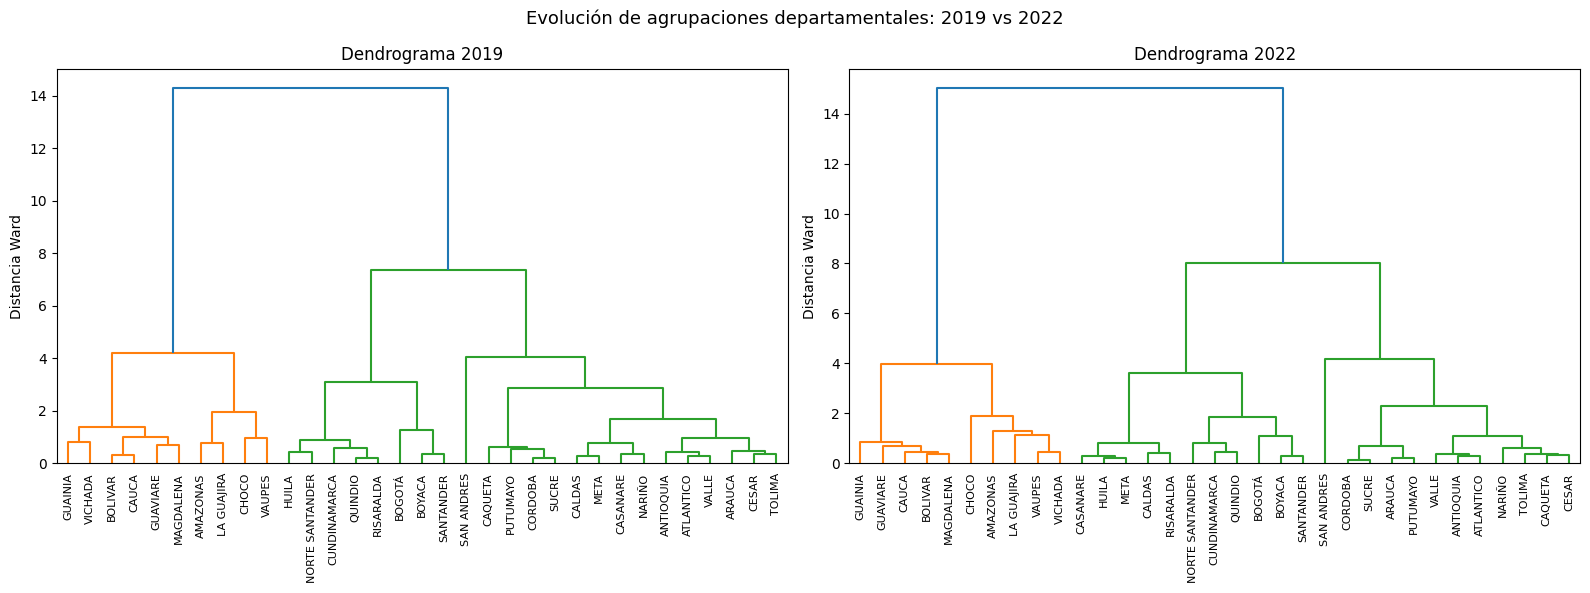


Grupos 2019: {'Medio': 15, 'Bajo': 10, 'Alto': 8}
Grupos 2022: {'Medio': 12, 'Alto': 11, 'Bajo': 10}

Departamentos que cambiaron de grupo: 3
   Depto Grupo_2019 Grupo_2022  Prom_2019  Prom_2022
  CALDAS      Medio       Alto       49.3       50.7
CASANARE      Medio       Alto       49.0       50.4
    META      Medio       Alto       49.5       50.5

=== Promedio nacional por período (todos los estudiantes) ===
PERIODO                    20194   20224
PUNT_LECTURA_CRITICA       52.17   52.78
PUNT_MATEMATICAS           50.63   50.56
PUNT_C_NATURALES           48.26   49.07
PUNT_SOCIALES_CIUDADANAS   46.23   47.69
PUNT_INGLES                48.47   49.84
PUNT_GLOBAL               246.27  250.04

Promedio simple de departamentos — 2019: 47.40 | 2022: 48.33
Departamentos que subieron: 31 de 33


In [7]:
# TODO 1: promedios por departamento y período
col_periodo = "PERIODO"
prof_2019 = df[df[col_periodo]==20194].groupby("COLE_DEPTO_UBICACION")[PUNTAJES].mean().dropna()
prof_2022 = df[df[col_periodo]==20224].groupby("COLE_DEPTO_UBICACION")[PUNTAJES].mean().dropna()
deptos_comunes = prof_2019.index.intersection(prof_2022.index)
prof_2019 = prof_2019.loc[deptos_comunes]
prof_2022 = prof_2022.loc[deptos_comunes]
print(f"Departamentos comunes 2019-2022: {len(deptos_comunes)}")

# TODO 2-3: clustering jerárquico + dendrogramas
# Se usa el mismo escalador (ajustado con 2019) para que ambos años queden en la misma escala
sc = StandardScaler().fit(prof_2019)
X_2019 = sc.transform(prof_2019)
X_2022 = sc.transform(prof_2022)
linked_2019 = linkage(X_2019, method='ward')
linked_2022 = linkage(X_2022, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, linked, etiquetas, titulo in [
    (axes[0], linked_2019, prof_2019.index.tolist(), "Dendrograma 2019"),
    (axes[1], linked_2022, prof_2022.index.tolist(), "Dendrograma 2022")]:
    dendrogram(linked, labels=etiquetas, ax=ax, leaf_rotation=90, leaf_font_size=8)
    ax.set_title(titulo)
    ax.set_ylabel("Distancia Ward")
plt.suptitle("Evolución de agrupaciones departamentales: 2019 vs 2022", fontsize=13)
plt.tight_layout(); plt.show()

# TODO 4: departamentos que cambiaron de cluster
etiq_2019 = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_2019)
etiq_2022 = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_2022)

# Los números de cluster son arbitrarios en cada año, así que se renombran
# según su puntaje promedio: Bajo, Medio, Alto
def nombrar_grupos(etiquetas, prof):
    medias = prof.mean(axis=1).groupby(etiquetas).mean().sort_values()
    nombres = dict(zip(medias.index, ["Bajo", "Medio", "Alto"]))
    return [nombres[e] for e in etiquetas]

cambios = pd.DataFrame({"Depto": deptos_comunes,
                        "Grupo_2019": nombrar_grupos(etiq_2019, prof_2019),
                        "Grupo_2022": nombrar_grupos(etiq_2022, prof_2022),
                        "Prom_2019": prof_2019.mean(axis=1).values.round(1),
                        "Prom_2022": prof_2022.mean(axis=1).values.round(1)})
print("\nGrupos 2019:", cambios["Grupo_2019"].value_counts().to_dict())
print("Grupos 2022:", cambios["Grupo_2022"].value_counts().to_dict())
cambios_reales = cambios[cambios["Grupo_2019"] != cambios["Grupo_2022"]]
print(f"\nDepartamentos que cambiaron de grupo: {len(cambios_reales)}")
print(cambios_reales.to_string(index=False))

# TODO 5: análisis comparativo
print("\n=== Promedio nacional por período (todos los estudiantes) ===")
print(df.groupby(col_periodo)[PUNTAJES + ["PUNT_GLOBAL"]].mean().round(2).T)
print(f"\nPromedio simple de departamentos — 2019: {prof_2019.mean().mean():.2f} | 2022: {prof_2022.mean().mean():.2f}")
subieron = (cambios["Prom_2022"] > cambios["Prom_2019"]).sum()
print(f"Departamentos que subieron: {subieron} de {len(cambios)}")

**Análisis Tarea 4:**

- **Ojo con las etiquetas:** los números de cluster (0, 1, 2) que da el clustering en 2019 y en 2022 son arbitrarios, así que no se pueden comparar directamente. Por eso se renombraron según el puntaje promedio de cada grupo (Bajo, Medio, Alto). Además se usó el mismo escalador (ajustado con 2019) en los dos años, para que una mejora general no se pierda al estandarizar cada año por separado.
- **Departamentos que cambiaron de grupo:** **Caldas, Casanare y Meta** pasaron de "Medio" a "Alto" (cada uno subió entre 1 y 1,4 puntos de promedio). El grupo Alto pasó de 8 a 11 departamentos y el grupo Bajo se quedó con 10.
- **¿Colombia mejoró?** Sí, pero poco. El puntaje global nacional pasó de 246,3 a 250,0 (+3,8 puntos), 31 de los 33 departamentos subieron y mejoraron sociales (+1,5), inglés (+1,4), naturales (+0,8) y lectura (+0,6). Matemáticas se quedó igual (-0,07).
- Aun así, con estos datos no se puede afirmar con certeza que la educación mejoró: es una muestra de un solo período por año, los estudiantes que presentan la prueba pueden ser distintos y en 2022 todavía estaba el efecto de la pandemia. Para responder mejor usaríamos: el **promedio ponderado por número de estudiantes** (no el promedio simple de departamentos), **intervalos de confianza o una prueba t** para ver si la diferencia es significativa, la **distribución completa** (percentiles, % de estudiantes en niveles bajos) y si se **cerraron las brechas** oficial/privado y urbano/rural.

## Tarea 5 (10 min) — Clustering en el P2/3

1. Sobre el dataset del proyecto de tu grupo, aplica K-Means (o DBSCAN si tiene sentido) como el **modelo no supervisado requerido** en la Fase C.
2. Calcula el Silhouette Score.
3. Describe en 3-4 frases qué significan los clusters encontrados en términos del negocio/dominio de tu dataset.

Días analizados: 3,220


K=2  silhouette=0.2249


K=3  silhouette=0.2074


K=4  silhouette=0.1984
K=5  silhouette=0.2007


K=6  silhouette=0.1746



Silhouette Score del proyecto (K=3): 0.2074

=== Perfil de cada cluster ===
         reportes  pct_confirmados  lesionados  fallecidos  vehiculos_prom  \
cluster                                                                      
0          173.57             0.34       19.74        1.13            1.96   
1           60.28             0.44       11.88        1.16            1.87   
2           78.21             0.29       10.38        0.86            1.94   

         pct_moto  
cluster            
0            0.17  
1            0.30  
2            0.18  

Días por año en cada cluster:
cluster    0    1    2
anio                  
2016     340    2   24
2017     307    9   49
2018     302   19   44
2019     304   18   43
2020      65  216   85
2021      33  156  176
2022      29   31  305
2023       0   59  298
2024       0  201  105


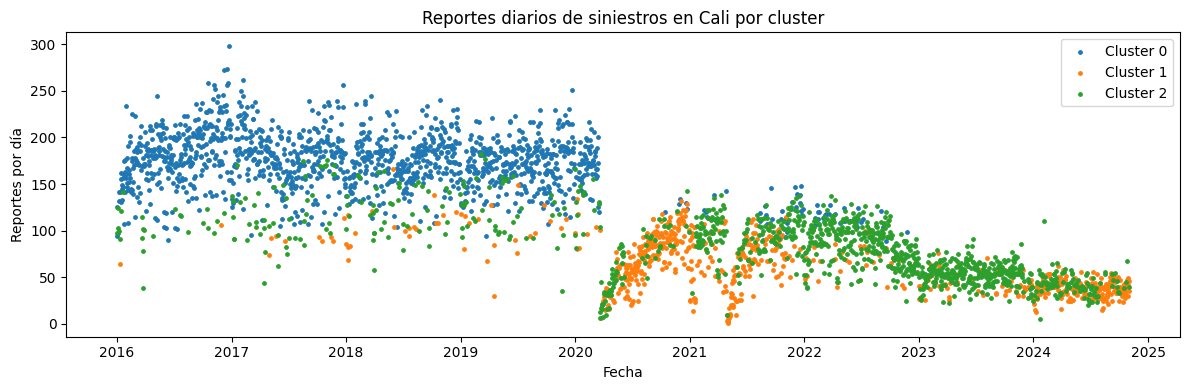

In [8]:
# Dataset del proyecto: Siniestralidad vial de Cali 2016-2024
df_proyecto = pd.read_csv("../siniestralidad_2016_2024.csv", sep=";", encoding="latin-1",
                          na_values=["."], low_memory=False)
df_proyecto.columns = ["Codigo","Fecha","Tipo_confirmado","Direccion","Clase_accidente","Clase_accidente_2",
                       "Tipo_confirmado_2","Medio_reporte","Num_vehiculos","Vehiculos"]
df_proyecto = df_proyecto.drop_duplicates()
df_proyecto["Fecha"] = pd.to_datetime(df_proyecto["Fecha"], format="%d/%m/%Y", errors="coerce")

# Variables 0/1 a partir de la gravedad y del tipo de vehículo
gravedad = df_proyecto["Tipo_confirmado"].str.upper()
df_proyecto["confirmado"] = (gravedad != "NEGATIVO").astype(int)
df_proyecto["lesionado"] = gravedad.str.contains("LESIONADO").astype(int)
df_proyecto["fallecido"] = gravedad.str.contains("FALLECIDO").astype(int)
df_proyecto["moto"] = df_proyecto["Vehiculos"].str.contains("MOTO", na=False).astype(int)

# Cada fila de "dias" es un día en Cali, descrito por cuántos siniestros hubo y qué tan graves fueron
dias = df_proyecto.groupby("Fecha").agg(
    reportes=("Codigo","count"),
    pct_confirmados=("confirmado","mean"),
    lesionados=("lesionado","sum"),
    fallecidos=("fallecido","sum"),
    vehiculos_prom=("Num_vehiculos","mean"),
    pct_moto=("moto","mean")).dropna()
print(f"Días analizados: {len(dias):,}")

features = ["reportes","pct_confirmados","lesionados","fallecidos","vehiculos_prom","pct_moto"]
X_proy = StandardScaler().fit_transform(dias[features])

# Probar K de 2 a 6 con Silhouette
for k in range(2, 7):
    etiquetas_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_proy)
    print(f"K={k}  silhouette={silhouette_score(X_proy, etiquetas_k):.4f}")

K_proy = 3
km_proy = KMeans(n_clusters=K_proy, n_init=10, random_state=42)
labels_proy = km_proy.fit_predict(X_proy)
sil_proy = silhouette_score(X_proy, labels_proy)
print(f"\nSilhouette Score del proyecto (K={K_proy}): {sil_proy:.4f}")

dias["cluster"] = labels_proy
dias["anio"] = dias.index.year
print("\n=== Perfil de cada cluster ===")
print(dias.groupby("cluster")[features].mean().round(2))
print("\nDías por año en cada cluster:")
print(pd.crosstab(dias["anio"], dias["cluster"]))

fig, ax = plt.subplots(figsize=(12, 4))
for k in range(K_proy):
    m = dias["cluster"] == k
    ax.scatter(dias.index[m], dias["reportes"][m], s=6, label=f"Cluster {k}")
ax.set_title("Reportes diarios de siniestros en Cali por cluster")
ax.set_xlabel("Fecha"); ax.set_ylabel("Reportes por día"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación de negocio de los clusters (Siniestralidad vial de Cali 2016-2024):**

Agrupamos los **3.220 días** del dataset según el número de reportes, el % confirmado, los lesionados, los fallecidos, el promedio de vehículos y el % de casos con moto. Con K=3 el **Silhouette es 0,207**, que es bajo: los días no forman grupos muy separados. El **cluster 0 – "Días de alto volumen"** tiene unos 174 reportes diarios y casi 20 lesionados, y corresponde casi todo a 2016-2019. El **cluster 1 – "Días de bajo volumen con más motos"** tiene unos 60 reportes, pero un mayor % confirmado (44 %) y más motos (30 %). Ahí cae la mayoría de 2020 (pandemia) y de 2024. El **cluster 2 – "Días intermedios"** (unos 78 reportes) domina en 2021-2023. Para el negocio, esto muestra que los clusters reflejan sobre todo **cambios en el tiempo** (pandemia y posiblemente cambios en cómo se reportan los casos) más que tipos de día. Para el proyecto convendría repetir el clustering dentro de cada año o usar otras variables, como la zona de la ciudad.

## Entrega

**Nombre del archivo:** `02_laboratorio_apellido1_apellido2.ipynb`

**Sube a:** Moodle → Clase 7 → Laboratorio.

**Criterios de evaluación:**
- Tareas 1-4: código funcional + análisis escrito de los resultados
- Tarea 5: aplicado al dataset del proyecto con interpretación de negocio
- Reflexiones escritas en celdas markdown